# 第 4 课 · 价格内生性与需求识别

商店能看出有些顾客特别想买，便倾向于向这些顾客报更高的价。研究者只看到报价和成交记录。如果直接用这些数据估计需求，会得到怎样的价格系数？

**建议用时 60 分钟。** 本课回到[第一课](01-binary-logit.ipynb)的一件商品，把[第二课](02-sampling-uncertainty.ipynb)的重复抽样方法用在两种报价规则上。你将写出识别价格系数所需的条件，并检查扩大样本怎样影响估计的波动与估计值所在的位置。

## 1. 购买模型保持不变

顾客 $i$ 面对报价 $p_i$。购买与不购买的效用差仍是

$$
\Delta U_i=\alpha+\beta(p_i-8)+\varepsilon_i,
\qquad
y_i=\mathbf{1}[\Delta U_i\ge 0],
\qquad
(\alpha,\beta)=(0.60,-0.55).
$$

顾客的冲击 $\varepsilon_i$ 独立抽自标准 Logistic 分布，分布函数为 $\Lambda(z)=1/(1+e^{-z})$。若给同一顾客群体统一报价 $p$，模型预测的购买率是 $\Lambda(\alpha+\beta(p-8))$。因此在这个模型里，提价会降低购买率。

### 两种报价规则

| 规则 | 商店怎样报价 |
| --- | --- |
| 随机报价 | 独立于顾客的冲击，从 5 至 11 元的整数价中等概率抽取一个报价。 |
| 内生报价 | 每位顾客有 70% 的概率按购买意愿报价，有 30% 的概率按同样的方式随机报价。按购买意愿报价时，商店把冲击从低到高按七个等概率区间分组，分别报 5 至 11 元。 |

由于 $u_i=\Lambda(\varepsilon_i)$ 在 $[0,1]$ 上均匀分布，按购买意愿报价时，每档价格也有 $1/7$ 的概率。两种规则下的**价格分布相同**，但同一档报价对应的顾客可能不同。内生报价中的随机分支使每一档价格仍有机会报给不同购买意愿的顾客。在模拟里我们看得到冲击，以便核对报价机制。在估计时，研究者只使用报价 $p_i$ 和购买结果 $y_i$。

In [1]:
import matplotlib.pyplot as plt
import numpy as np
from matplotlib.ticker import PercentFormatter
from scipy.optimize import minimize
from scipy.special import expit

reference_price = 8.0
price_levels = np.arange(5, 12)
true_intercept = 0.60
true_slope = -0.55
sorting_share = 0.70


def simulate_pair(sample_size, rng, sorting_share):
    shock = rng.logistic(size=sample_size)
    random_price = rng.choice(price_levels, size=sample_size)

    # 商店把购买意愿的百分位映射到七档价格。
    percentile = expit(shock)
    rank = np.floor(len(price_levels) * percentile).astype(int)
    sorted_price = price_levels[np.minimum(rank, len(price_levels) - 1)]
    sorts = rng.random(sample_size) < sorting_share
    endogenous_price = np.where(sorts, sorted_price, random_price)

    random_purchase = (
        true_intercept + true_slope * (random_price - reference_price) + shock >= 0
    ).astype(int)
    endogenous_purchase = (
        true_intercept + true_slope * (endogenous_price - reference_price) + shock >= 0
    ).astype(int)
    return random_price, random_purchase, endogenous_price, endogenous_purchase, shock


example = simulate_pair(2_000, np.random.default_rng(421), sorting_share)
random_price, random_purchase, endogenous_price, endogenous_purchase, shock = example

print("报价与未观测冲击的样本相关系数")
print(f"随机报价：{np.corrcoef(random_price, shock)[0, 1]:+.3f}")
print(f"内生报价：{np.corrcoef(endogenous_price, shock)[0, 1]:+.3f}")
print()
print(f"{'报价（元）':<10}{'随机报价人数':<14}{'内生报价人数'}")
for price in price_levels:
    print(
        f"{price:<13}{(random_price == price).sum():<17}"
        f"{(endogenous_price == price).sum()}"
    )

报价与未观测冲击的样本相关系数
随机报价：+0.020
内生报价：+0.673

报价（元）     随机报价人数        内生报价人数
5            272              279
6            303              279
7            280              306
8            291              311
9            313              278
10           286              262
11           255              285


## 2. 为什么同一价格下的顾客不一样？

随机报价使价格 $P$ 与冲击 $\varepsilon$ 独立。同一价格下的样本购买率可以用来估计给整个顾客群体统一报这个价时的购买率。在本课的效用设定下，把这些购买率转换成对数胜算后，任意两个价格对应的对数胜算之差除以价差，就得到总体的 $\beta$。样本中的购买率有抽样误差，所以我们仍用极大似然拟合所有价格档位。

内生报价时，知道 $P$ 就能推断部分关于 $\varepsilon$ 的信息。观测到的条件购买率 $\Pr(Y=1\mid P=p)$ 同时取决于价格带来的效用变化和报到该价格的人群构成。下面比较模拟样本中各档价格的购买率，并画出同一人群统一报价时的模型购买率。

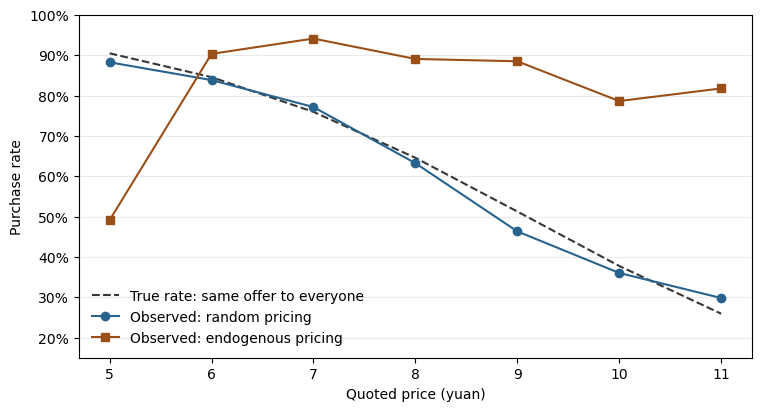

In [2]:
def purchase_rate_by_price(price, purchase):
    return np.array([purchase[price == level].mean() for level in price_levels])


true_purchase_rate = expit(true_intercept + true_slope * (price_levels - reference_price))
fig, axis = plt.subplots(figsize=(7.5, 4.0), layout="constrained")
axis.plot(
    price_levels, true_purchase_rate, "--", color="#363636",
    label="True rate: same offer to everyone",
)
axis.plot(
    price_levels, purchase_rate_by_price(random_price, random_purchase),
    "o-", color="#28638e", label="Observed: random pricing",
)
axis.plot(
    price_levels, purchase_rate_by_price(endogenous_price, endogenous_purchase),
    "s-", color="#9a4f18", label="Observed: endogenous pricing",
)
axis.set(xlabel="Quoted price (yuan)", ylabel="Purchase rate", xticks=price_levels, ylim=(0.15, 1.0))
axis.yaxis.set_major_formatter(PercentFormatter(xmax=1))
axis.grid(axis="y", alpha=0.25)
axis.legend(loc="lower left", frameon=False)
plt.show()

随机报价下，样本的各档购买率围绕统一报价的曲线波动。内生报价下，各档购买率受报价对象的构成影响，图中的点也未必沿着一个方向变化。

## 3. 用同一个 Logit 估计，再扩大样本

无论报价机制是什么，我们都先用第一课的二元 Logit 去拟合数据，只让拟合程序看到报价与购买结果。然后在每个样本量下生成 250 对样本。每一对共用同一批顾客的冲击，也共用随机报价分支的价格抽签，比较的是将同一批顾客置于两种报价规则下的估计结果。不同对之间重新生成数据。

表中的「估计均值减去真值」衡量模拟中的系统偏离，「估计标准差」衡量不同样本之间的波动。

In [3]:
def fit_binary_logit(price, outcome):
    centered_price = price - reference_price

    def loss_and_gradient(parameters):
        intercept, slope = parameters
        index = intercept + slope * centered_price
        # 逐项写成稳定的对数形式。outcome 可以是 0/1，也可以是购买率。
        losses = outcome * np.logaddexp(0, -index) + (1 - outcome) * np.logaddexp(0, index)
        residual = expit(index) - outcome
        gradient = np.array([residual.mean(), (residual * centered_price).mean()])
        return losses.mean(), gradient

    fit = minimize(
        loss_and_gradient, np.zeros(2), jac=True, method="BFGS", options={"gtol": 1e-7}
    )
    if not fit.success or not np.all(np.isfinite(fit.x)):
        raise RuntimeError(f"二元 Logit 拟合失败：{fit.message}")
    return fit.x


def repeat_estimation(sample_size, repetitions, rng, sorting_share):
    result = np.empty((repetitions, 2))
    for draw in range(repetitions):
        price_r, purchase_r, price_e, purchase_e, _ = simulate_pair(sample_size, rng, sorting_share)
        for column, (price, purchase) in enumerate(((price_r, purchase_r), (price_e, purchase_e))):
            try:
                result[draw, column] = fit_binary_logit(price, purchase)[1]
            except RuntimeError as error:
                rule = ("随机报价", "内生报价")[column]
                raise RuntimeError(
                    f"样本人数 {sample_size}，第 {draw + 1} 次，{rule}：{error}"
                ) from error
    return result


sample_sizes = (200, 2_000)
repetitions = 250
simulation_rng = np.random.default_rng(202604)
estimates = {
    size: repeat_estimation(size, repetitions, simulation_rng, sorting_share)
    for size in sample_sizes
}

print(f"真实价格系数 {true_slope:+.3f}，每个样本量重复 {repetitions} 次")
print(f"{'n':>6} {'Pricing rule':<13} {'Mean slope':>11} {'Mean - truth':>13} {'SD':>9}")
for size, slopes in estimates.items():
    for rule, values in zip(("Random", "Endogenous"), slopes.T):
        mean_slope = values.mean()
        print(
            f"{size:>6,} {rule:<13} {mean_slope:>+11.3f} "
            f"{mean_slope - true_slope:>+13.3f} {values.std(ddof=1):>9.3f}"
        )

真实价格系数 -0.550，每个样本量重复 250 次
     n Pricing rule   Mean slope  Mean - truth        SD
   200 Random             -0.557        -0.007     0.093
   200 Endogenous         +0.142        +0.692     0.102
 2,000 Random             -0.551        -0.001     0.029
 2,000 Endogenous         +0.135        +0.685     0.034


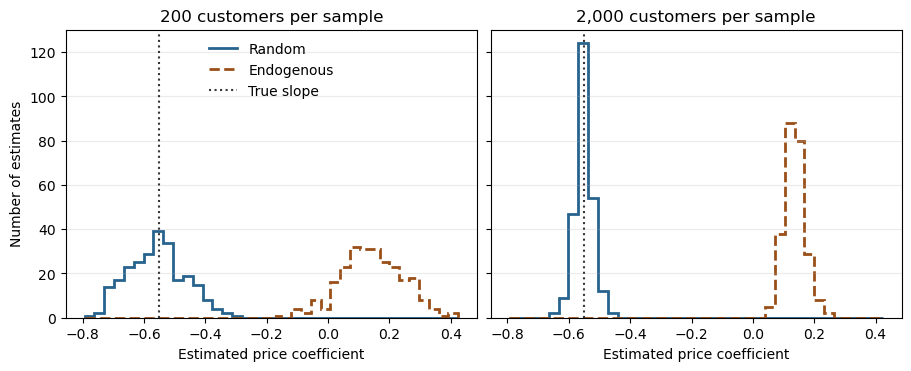

In [4]:
common_bins = np.histogram_bin_edges(np.concatenate(list(estimates.values())).ravel(), bins=38)
panels = len(estimates)
figure, axes = plt.subplots(
    1, panels, figsize=(4.5 * panels, 3.6), sharex=True, sharey=True, layout="constrained"
)
axes = np.atleast_1d(axes)
for axis, (size, slopes) in zip(axes, estimates.items()):
    for label, color, style, values in zip(
        ("Random", "Endogenous"), ("#28638e", "#9a4f18"), ("-", "--"), slopes.T
    ):
        counts, _ = np.histogram(values, bins=common_bins)
        axis.stairs(counts, common_bins, label=label, color=color, linestyle=style, linewidth=2)
    axis.axvline(true_slope, color="#363636", linestyle=":", label="True slope")
    axis.set(title=f"{size:,} customers per sample", xlabel="Estimated price coefficient")
    axis.grid(axis="y", alpha=0.25)
axes[0].set_ylabel("Number of estimates")
axes[0].legend(loc="upper center", frameon=False)
plt.show()

默认设置下，两种报价规则的估计波动都随着样本扩大而缩小。随机报价下的估计均值接近 $-0.55$。内生报价下，估计集中在正数附近，甚至颠倒了价格效应的符号。在这组参数和报价规则下，某条拟合曲线可以有正斜率，尽管给同一顾客提高报价会降低购买的可能性。内生性造成的偏离方向取决于报价规则和需求。

### 选读：内生报价的拟合值会靠近哪里？

令 $j=p-5$ 表示价格档位，从 $0$ 到 $6$。在按购买意愿报价的分支，报价 $p$ 意味着 $u_i$ 均匀分布在 $[j/7,(j+1)/7)$ 上。购买需要 $u_i\ge 1-q(p)$，其中 $q(p)$ 是同一人群统一报价时的购买率。区间内落在购买阈值以上的比例由下式计算，结果限制在 0 和 1 之间。

$$
q_{\mathrm{sort}}(p)=\min\{1,\max\{0,j+1-7[1-q(p)]\}\}.
$$

两个分支的价格边际分布一样，因而在每档价格中都按同样的比例混合两种购买率。用这个总体购买率替换样本中的 0/1 结果，等权拟合七档价格，得到这个实验中普通 Logit 的总体拟合值。随着样本扩大，各档购买率接近对应的总体购买率，估计系数会接近下面的拟合值。

In [5]:
rank = price_levels - price_levels[0]
sorted_purchase_rate = np.clip(rank + 1 - len(price_levels) * (1 - true_purchase_rate), 0, 1)
endogenous_purchase_rate = (
    (1 - sorting_share) * true_purchase_rate + sorting_share * sorted_purchase_rate
)
population_random = fit_binary_logit(price_levels, true_purchase_rate)
population_endogenous = fit_binary_logit(price_levels, endogenous_purchase_rate)

print(f"随机报价下的总体拟合斜率：{population_random[1]:+.4f}")
print(f"内生报价下的总体拟合斜率：{population_endogenous[1]:+.4f}")

随机报价下的总体拟合斜率：-0.5500
内生报价下的总体拟合斜率：+0.1360


## 4. 哪些价格变动有助于识别需求？

如果商店能随机分配报价，并记录所有顾客看到的报价和购买结果，就可以利用这部分价格变动来学习顾客对价格的反应。

**选读。** 在无法随机报价时，有时可以寻找**工具变量**（instrumental variable），例如一项可能改变商店报价的成本冲击。候选工具需要能引起价格变化，与未观测的需求因素独立，并且只能通过价格影响购买。成本冲击是否满足这些条件，要结合具体的制度和数据判断。二元 Logit 中还需要相应的估计方法来利用候选工具所提供的信息。 [Train《Discrete Choice Methods with Simulation》第 13 章](https://eml.berkeley.edu/books/choice2nd/Ch13_p315-346.pdf)

[第五课](05-pricing-counterfactual-project.ipynb)会用随机报价估计需求，再比较商店的定价方案。

## 练习

1. 将 `sorting_share` 改为 `0.0` 并重新运行。两种报价下每位顾客收到的报价和选择是否一致？用它们共用的价格抽签解释结果。
2. 保持 `sorting_share = 0.70`，在 `sample_sizes` 中加入 `8_000`。两种报价规则下估计的标准差如何变化？用总体拟合值解释内生报价下的斜率为何仍偏离 $-0.55$。
3. 分别用两种报价下的总体拟合参数 `population_random`、`population_endogenous`，计算统一报价从 8 元调到 9 元时的购买率变化。用百分点报告结果。这两个预测对商店的决策有何不同含义？
4. 假设配送成本上升时，商店既提高报价，也延长交货时间。若顾客在意交货时间，该成本变化作为价格工具变量可能违反哪项条件？